In [1]:
   import pandas as pd

   df = pd.read_csv('../data/superstore_clean.csv', parse_dates=['Order Date', 'Ship Date'])

   print(df.shape)
   df.dtypes[['Order Date', 'Ship Date']]

(9994, 22)


Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object

In [2]:
   total_sales = df['Sales'].sum()
   total_profit = df['Profit'].sum()
   total_orders = df['Order ID'].nunique()
   avg_order_value = total_sales / total_orders
   profit_margin = total_profit / total_sales * 100

   print(f"Total Sales:       {total_sales:,.2f}")
   print(f"Total Profit:      {total_profit:,.2f}")
   print(f"Total Orders:      {total_orders:,}")
   print(f"Avg Order Value:   {avg_order_value:,.2f}")
   print(f"Profit Margin:     {profit_margin:.2f}%")

Total Sales:       2,297,200.86
Total Profit:      286,397.02
Total Orders:      5,009
Avg Order Value:   458.61
Profit Margin:     12.47%


In [3]:
   df['Year'] = df['Order Date'].dt.year

   yearly = df.groupby('Year').agg(
       Sales=('Sales', 'sum'),
       Profit=('Profit', 'sum'),
       Orders=('Order ID', 'nunique')
   ).round(2)

   yearly

,Sales,Profit,Orders
Year,,,
2014,484247.50,49543.97,969
2015,470532.51,61618.60,1038
2016,609205.60,81795.17,1315
2017,733215.26,93439.27,1687


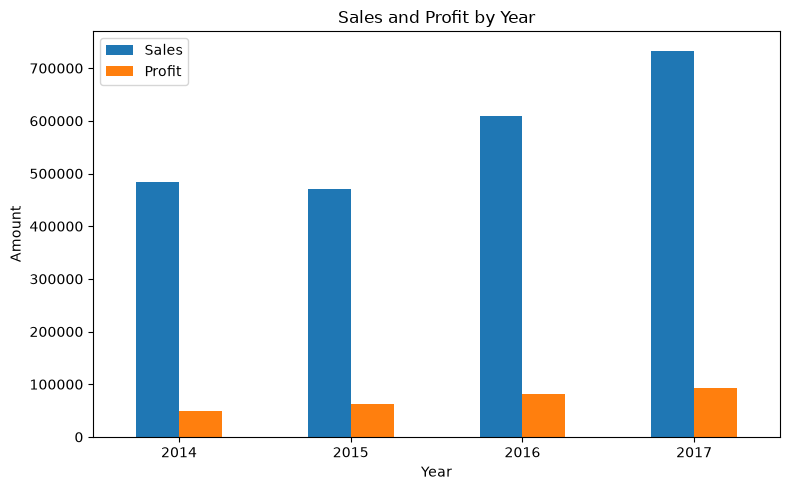

In [5]:
   import matplotlib.pyplot as plt

   ax = yearly[['Sales', 'Profit']].plot(kind='bar', figsize=(8, 5))
   ax.set_title('Sales and Profit by Year')
   ax.set_xlabel('Year')
   ax.set_ylabel('Amount')
   plt.xticks(rotation=0)
   plt.tight_layout()
   plt.savefig('../screenshots/sales_profit_by_year.png', dpi=150)
   plt.show()

In [6]:
   category = df.groupby('Category').agg(
       Sales=('Sales', 'sum'),
       Profit=('Profit', 'sum'),
       Orders=('Order ID', 'nunique')
   ).round(2)

   category['Margin %'] = (category['Profit'] / category['Sales'] * 100).round(2)

   category.sort_values('Profit', ascending=False)

,Sales,Profit,Orders,Margin %
Category,,,,
Technology,836154.03,145454.95,1544,17.40
Office Supplies,719047.03,122490.80,3742,17.04
Furniture,741999.80,18451.27,1764,2.49


In [7]:
   subcat = df.groupby(['Category', 'Sub-Category']).agg(
       Sales=('Sales', 'sum'),
       Profit=('Profit', 'sum')
   ).round(2)

   subcat['Margin %'] = (subcat['Profit'] / subcat['Sales'] * 100).round(2)

   subcat.sort_values('Profit')

Sales    Profit  Margin %
Category        Sub-Category                               
Furniture       Tables        206965.53 -17725.48     -8.56
                Bookcases     114880.00  -3472.56     -3.02
Office Supplies Supplies       46673.54  -1189.10     -2.55
                Fasteners       3024.28    949.52     31.40
Technology      Machines      189238.63   3384.76      1.79
Office Supplies Labels         12486.31   5546.25     44.42
                Art            27118.79   6527.79     24.07
                Envelopes      16476.40   6964.18     42.27
Furniture       Furnishings    91705.16  13059.14     14.24
Office Supplies Appliances    107532.16  18138.01     16.87
                Storage       223843.61  21278.83      9.51
Furniture       Chairs        328449.10  26590.17      8.10
Office Supplies Binders       203412.73  30221.76     14.86
                Paper          78479.21  34053.57     43.39
Technology      Accessories   167380.32  41936.64     25.05
                Phones        330007.05  44515.73     13.49
                Copiers       149528.03  55617.82     37.20

In [8]:
   tables = df[df['Sub-Category'] == 'Tables']

   tables_by_discount = tables.groupby('Discount').agg(
       Rows=('Row ID', 'count'),
       Sales=('Sales', 'sum'),
       Profit=('Profit', 'sum')
   ).round(2)

   tables_by_discount

,Rows,Sales,Profit
Discount,,,
0.00,72,71578.76,13276.30
0.20,71,45430.23,-303.56
0.30,54,25182.15,-3402.33
0.40,75,45614.41,-16187.40
0.45,11,5484.97,-2493.11
0.50,36,13675.01,-8615.39


In [9]:
   bins = [-0.01, 0, 0.2, 0.4, 1]
   labels = ['0%', '1-20%', '21-40%', 'Over 40%']

   df['Discount Band'] = pd.cut(df['Discount'], bins=bins, labels=labels)

   discount_bands = df.groupby('Discount Band', observed=True).agg(
       Rows=('Row ID', 'count'),
       Sales=('Sales', 'sum'),
       Profit=('Profit', 'sum')
   ).round(2)

   discount_bands['Margin %'] = (discount_bands['Profit'] / discount_bands['Sales'] * 100).round(2)

   discount_bands

,Rows,Sales,Profit,Margin %
Discount Band,,,,
0%,4798,1087908.47,320987.60,29.51
1-20%,3803,846522.24,100785.47,11.91
21-40%,460,234137.90,-35817.47,-15.30
Over 40%,933,128632.25,-99558.59,-77.40


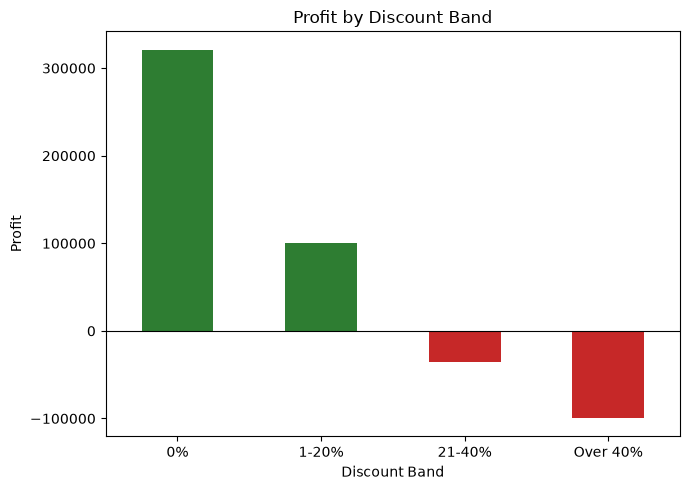

In [10]:
   colors = ['#2e7d32' if value >= 0 else '#c62828' for value in discount_bands['Profit']]

   ax = discount_bands['Profit'].plot(kind='bar', color=colors, figsize=(7, 5))
   ax.set_title('Profit by Discount Band')
   ax.set_xlabel('Discount Band')
   ax.set_ylabel('Profit')
   plt.axhline(0, color='black', linewidth=0.8)
   plt.xticks(rotation=0)
   plt.tight_layout()
   plt.savefig('../screenshots/profit_by_discount_band.png', dpi=150)
   plt.show()

In [11]:
   region = df.groupby('Region').agg(
       Sales=('Sales', 'sum'),
       Profit=('Profit', 'sum'),
       Orders=('Order ID', 'nunique')
   ).round(2)

   region['Margin %'] = (region['Profit'] / region['Sales'] * 100).round(2)

   region.sort_values('Profit', ascending=False)

,Sales,Profit,Orders,Margin %
Region,,,,
West,725457.82,108418.45,1611,14.94
East,678781.24,91522.78,1401,13.48
South,391721.90,46749.43,822,11.93
Central,501239.89,39706.36,1175,7.92


In [12]:
   region_discount = df.groupby('Region').agg(
       Avg_Discount_Pct=('Discount', lambda s: round(s.mean() * 100, 1)),
       Heavy_Discount_Pct=('Discount', lambda s: round((s > 0.2).mean() * 100, 1))
   )

   region_discount

,Avg_Discount_Pct,Heavy_Discount_Pct
Region,,
Central,24.0,27.7
East,14.5,16.2
South,14.7,10.6
West,10.9,3.7


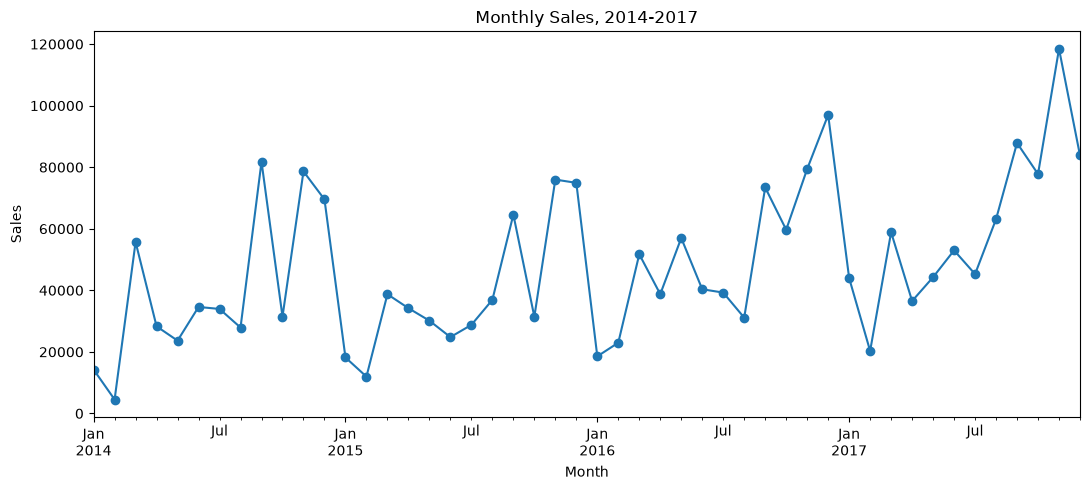

In [13]:
   df['Month'] = df['Order Date'].dt.to_period('M')

   monthly = df.groupby('Month').agg(
       Sales=('Sales', 'sum'),
       Profit=('Profit', 'sum')
   ).round(2)

   ax = monthly['Sales'].plot(figsize=(11, 5), marker='o')
   ax.set_title('Monthly Sales, 2014-2017')
   ax.set_xlabel('Month')
   ax.set_ylabel('Sales')
   plt.tight_layout()
   plt.savefig('../screenshots/monthly_sales.png', dpi=150)
   plt.show()

In [14]:
   df['Month Number'] = df['Order Date'].dt.month

   seasonal = df.groupby('Month Number').agg(
       Sales=('Sales', 'sum'),
       Profit=('Profit', 'sum')
   ).round(2)

   seasonal

,Sales,Profit
Month Number,,
1,94924.84,9134.45
2,59751.25,10294.61
3,205005.49,28594.69
4,137762.13,11587.44
5,155028.81,22411.31
6,152718.68,21285.80
7,147238.10,13832.66
8,159044.06,21776.94
9,307649.95,36857.48


In [15]:
   seasonal['Margin %'] = (seasonal['Profit'] / seasonal['Sales'] * 100).round(2)
   seasonal['Avg Discount %'] = (df.groupby('Month Number')['Discount'].mean() * 100).round(1)

   seasonal

,Sales,Profit,Margin %,Avg Discount %
Month Number,,,,
1,94924.84,9134.45,9.62,15.0
2,59751.25,10294.61,17.23,14.6
3,205005.49,28594.69,13.95,15.5
4,137762.13,11587.44,8.41,16.3
5,155028.81,22411.31,14.46,16.5
6,152718.68,21285.80,13.94,16.3
7,147238.10,13832.66,9.39,15.8
8,159044.06,21776.94,13.69,15.4
9,307649.95,36857.48,11.98,14.9
